**Large Language Models**

_Copyright Notice_

This notebook is available for educational purposes. You may not use or distribute this notebook for commercial purposes. You may make copies of this notebook and use or distribute it for educational purposes as long as you cite the author as the source of the notebook.

Jaeyoung Chun | School of Applied Artificial Intelligence | Handong Global University

# Multimodal - Image

## Load Environment Variables

In [1]:
from dotenv import load_dotenv

In [2]:
# retrieve API key and other environment variables
load_dotenv()

True

## Model

In [3]:
from langchain_openai import ChatOpenAI

In [4]:
model = ChatOpenAI(
    model_name="gpt-6-luna"
)

## Base64 Image

In [5]:
from IPython.display import Image

In [6]:
image_url = "./data/weather.jpeg"

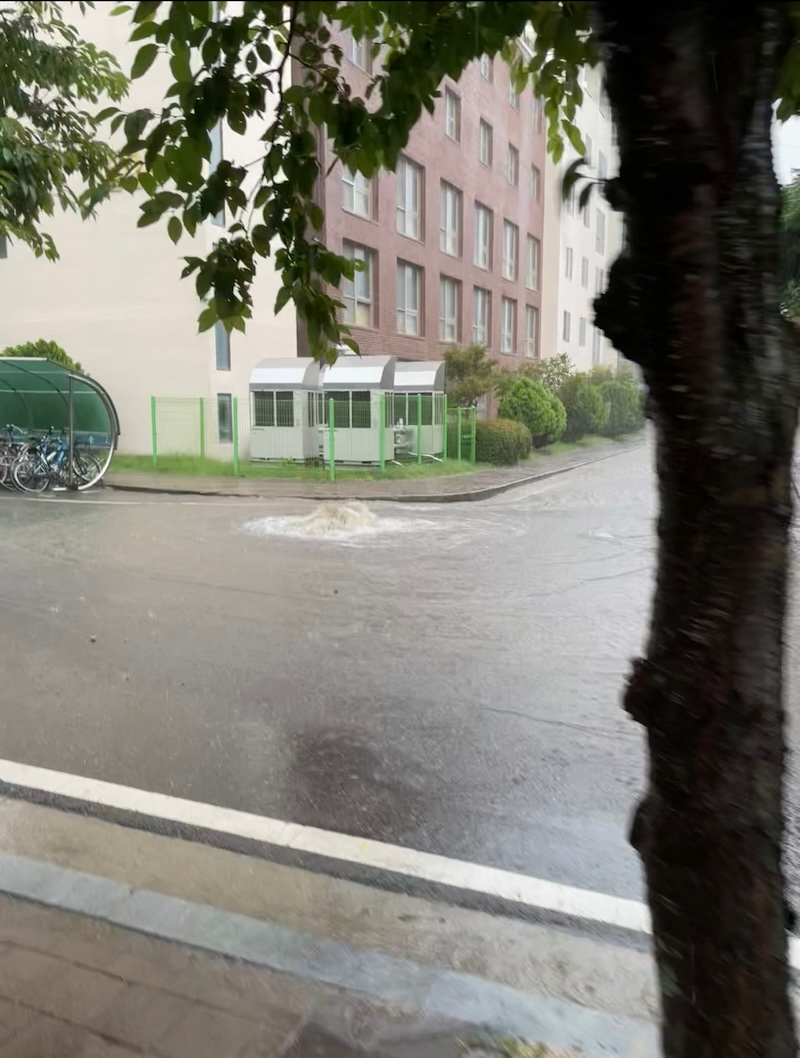

In [7]:
Image(filename=image_url)

In [8]:
import base64
import httpx

def png_file_to_base64(image_path):
    with open(image_path, "rb") as image_file:
        base64_string = base64.b64encode(image_file.read()).decode("utf-8")
    return base64_string
    
def png_url_to_base64(image_path):
    base64_string = base64.b64encode(httpx.get(image_url).content).decode("utf-8")
    return base64_string

In [9]:
image_data = png_file_to_base64(image_url)

In [10]:
len(image_data)

309624

In [11]:
image_data[-200:]

'hXn2of68fWnV+E7amyO20Mf6NV2IAXTYqloX/HtV6L/j7euY3hsdZoZPzVSm/wBcv1q5of8AFVOb/XL9aCjIveLhVHAbIPuKm8HqolkwO9Q33/Hyn41P4Q/10n1NdaPPr7ns2kVrt92sjSK12+7TpnOZkpPmivrT9joD/hOW47mvkqX/AFor62/Y6/5Hlvqa7DnP/9k='

## Construct Message with Image

In [12]:
from langchain_core.messages import HumanMessage

In [13]:
message = HumanMessage(
    content=[
        {
            "type": "text",
            "text": "이 사진의 상황을 묘사하고 분석한 후, 날씨가 어떤지를 설명해봐."
        },
        {
            "type": "image_url",
            "image_url": {"url": f"data:image/jpeg;base64,{image_data}"},
        },
    ],
)

## Invoke

In [14]:
response = model.invoke([message])

In [15]:
response

AIMessage(content='사진에는 건물과 자전거 보관대가 있는 도로가 담겨 있습니다. 도로와 보도가 물에 잠길 만큼 빗물이 많이 고였고, 교차로 쪽에서는 물이 솟거나 빠져나가며 작은 물보라가 일고 있습니다. 주변에 사람이 보이지 않는 점으로 보아, 이동하기 불편하거나 위험한 상황일 수 있습니다.\n\n비가 매우 세차게 내리는 중이거나 방금 집중호우가 지나간 것으로 보입니다. 하늘도 흐리고 지면 전체가 젖어 있어, 현재 날씨는 **폭우 또는 집중호우에 가까운 비 오는 날씨**로 판단됩니다. 다만 사진만으로는 비가 계속 내리는지, 일시적으로 그친 뒤 물이 흐르는지는 확정하기 어렵습니다.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 179, 'prompt_tokens': 1048, 'total_tokens': 1227, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-6-luna', 'system_fingerprint': None, 'id': 'chatcmpl-Ejmxanatcq22yF5C3iO2mfVBnPPFJ', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1d56

In [16]:
response.usage_metadata

{'input_tokens': 1048,
 'output_tokens': 179,
 'total_tokens': 1227,
 'input_token_details': {'audio': 0, 'cache_read': 0},
 'output_token_details': {'audio': 0, 'reasoning': 0}}

In [17]:
response.content

'사진에는 건물과 자전거 보관대가 있는 도로가 담겨 있습니다. 도로와 보도가 물에 잠길 만큼 빗물이 많이 고였고, 교차로 쪽에서는 물이 솟거나 빠져나가며 작은 물보라가 일고 있습니다. 주변에 사람이 보이지 않는 점으로 보아, 이동하기 불편하거나 위험한 상황일 수 있습니다.\n\n비가 매우 세차게 내리는 중이거나 방금 집중호우가 지나간 것으로 보입니다. 하늘도 흐리고 지면 전체가 젖어 있어, 현재 날씨는 **폭우 또는 집중호우에 가까운 비 오는 날씨**로 판단됩니다. 다만 사진만으로는 비가 계속 내리는지, 일시적으로 그친 뒤 물이 흐르는지는 확정하기 어렵습니다.'